In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA

# Load the dataset
wine = load_wine(as_frame=True)

df = wine.frame

## 1. Create a new train/test split

In [2]:
# Separate features and target
X = df.drop(columns = "target")
y = df["target"]

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Why was the data split this way.
- Splitting a test set from the data allows us to use it as an unbiased estimator of how well the model is generalising. 
- We also keep the test data unseen from the training data, like using the pipeline only on the training data, to prevent leakage
- A 80/20 split allows us to have enough data to train while also having enough data to evaluate the model

## 2. MLP with scalar pipeline

In [3]:
# Standardize: each feature gets mean 0 and standard deviation 1
mlp_pipeline = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(4,3), max_iter=500, random_state=42)
)

mlp_pipeline.fit(x_train,y_train)

test_acc = mlp_pipeline.score(x_test, y_test)
train_acc = mlp_pipeline.score(x_train, y_train)
print("Train Acc:", train_acc)
print("Test Acc:",test_acc)

Train Acc: 1.0
Test Acc: 1.0


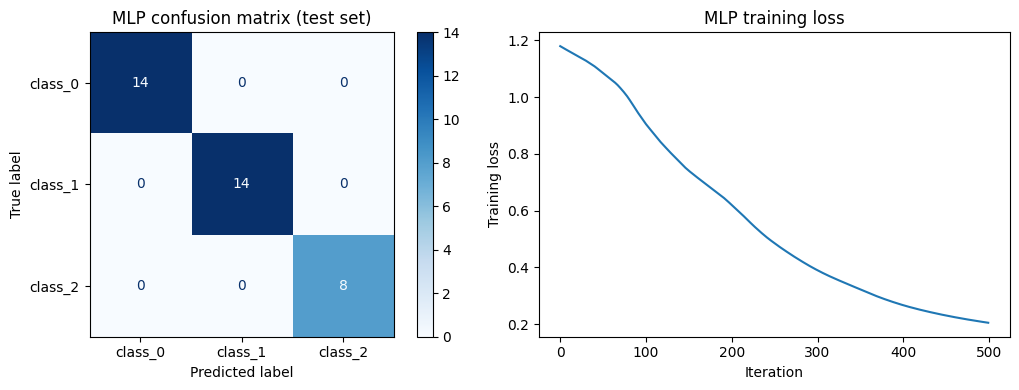

In [4]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Confusion matrix on the test set
ConfusionMatrixDisplay.from_estimator(
    mlp_pipeline, x_test, y_test,
    display_labels=wine.target_names, cmap="Blues", ax=axes[0]
)
axes[0].set_title("MLP confusion matrix (test set)")

# Training loss curve
axes[1].plot(mlp_pipeline[-1].loss_curve_)
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Training loss")
axes[1].set_title("MLP training loss")

plt.tight_layout()
plt.show()


1. What accuracy did your neural network achieve?
The MLP managed to get a train accuracy and test accuracy of 1.

2. How well does it classify each wine class?
The model was able to classify each wine class perfectly.

3. Why is feature scaling important for an MLP?
- It mainly affects how quickly and reliably the model is able to reach a minimum.
- Unscaled features can cause loss to be steep in the direction of the large-scale features, while shallow across the small-scale features. 
- A single learning rate needs to be large enough to make progress on the shallow floor, while small enough to to stay stable on the large-scale walls. Making it hard to balance, thus making gradient descent more challenging and training more time consuming.

4. What is the role of the hidden layer?
- The hidden layers are there to learn non-linear transformations. Which are only useful, since there are activations that introduce non-linearity.
- The non-linear transformations help to change the input space, which is non-linear, to a linearly seperable space. Such that the final layer, is able to make the final decision with a linear boundary.

## 3. Experiment with network architecture

  architecture  parameters  train_accuracy  test_accuracy
0         (5,)          88             1.0       0.972222
1        (10,)         173             1.0       0.972222
2        (20,)         343             1.0       1.000000
3        (50,)         853             1.0       1.000000
4     (20, 10)         523             1.0       1.000000
5     (50, 20)        1783             1.0       1.000000


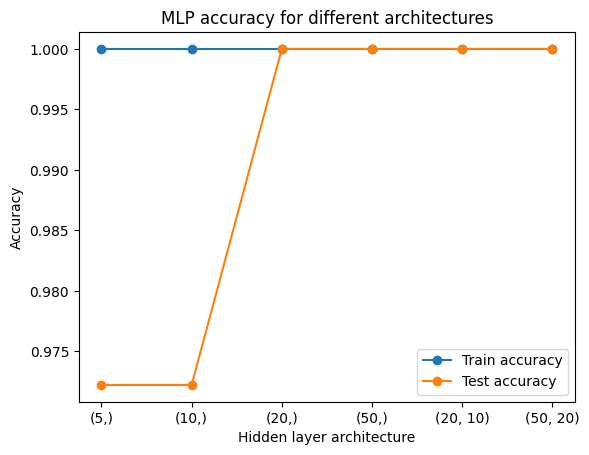

In [5]:
architectures = [(5,), (10,), (20,), (50,), (20, 10), (50, 20)]
results = []

for arch in architectures:
    model = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes = arch, max_iter = 1000, random_state = 42)
    )
    model.fit(x_train, y_train)
    n_params = sum(w.size for w in model[-1].coefs_) + sum(b.size for b in model[-1].intercepts_)
    results.append({
        "architecture": str(arch),
        "parameters": n_params,
        "train_accuracy": accuracy_score(y_train, model.predict(x_train)),
        "test_accuracy": accuracy_score(y_test, model.predict(x_test)),
    })

arch_df = pd.DataFrame(results)
print(arch_df)

# Plot
labels = [str(a) for a in architectures]
plt.plot(labels, arch_df["train_accuracy"], marker="o", label="Train accuracy")
plt.plot(labels, arch_df["test_accuracy"], marker="o", label="Test accuracy")
plt.xlabel("Hidden layer architecture")
plt.ylabel("Accuracy")
plt.title("MLP accuracy for different architectures")
plt.legend()
plt.show()

Questions:
1. Does increasing the number of neurons always improve performance?
- No 
- From 5 or 10 neurons to 20, the test accuracy improved from 0.972 (3sf) to 1.00 (3sf). However, beyond 20 neurons, there was no further improvement: (20,) and (50,) both reached 1.00.
- More neurons only help if the model is too simple for the problem. Once it has enough capacity, adding neurons just adds parameters without better generalization.

2. Does adding a second hidden layer improve the results?
- No
- (20, 10) and (50, 20) reach a test accuracy of 1.00, which is exactly the same as the single-layer (20,) and (50,) networks. 
- The wine classes are already well separable after standardization, so one hidden layer is enough and a second layer adds nothing.

3. What happens when the network becomes more complex?
- For this case, the extra complexity provides no real benefit. 
- The number of trainable parameters grows quickly from 88 for (5,) to 1783 for (50, 20). The training accuracy is already 1.00 for every architecture, and test accuracy stops improving after (20,). 
- Given that there are only 142 training samples, most of the networks (from (10,) onwards) have more parameters than training samples. The extra complexity only makes the model slower to train, harder to interpret, and more able to memorise noise in the training data.

4. What is the relationship between model complexity and overfitting?
- A more complex model has more parameters, so it can learn more detailed patterns. his also means it can more easily start memorising the training data, including random noise, instead of learning the general pattern. This is called overfitting, which can be recognised when the training accuracy is very high but the test accuracy is lower.
- A model that is too simple can’t learn the pattern well, so it does badly on both training and test data. This is called underfitting. 
- In our results, all networks reached a 100% training accuracy, so they are all complex enough to learn the training data. The bigger networks still scored 100% on the test set, so they don't overfit here. This is mainly because the wine dataset is small and easy to separate. On harder datasets, more complex networks would be more likely to overfit. 

## 4. Compare the neural network with previous models

In [6]:
from sklearn.ensemble import RandomForestClassifier

# Neural Network
mlp_pipeline.fit(x_train, y_train)
mlp_pred = mlp_pipeline.predict(x_test)
mlp_acc = accuracy_score(y_test, mlp_pred)

# Logistic Regression
log_model = make_pipeline(
   StandardScaler(),
   LogisticRegression(max_iter=1000, random_state=42)
)

log_model.fit(x_train, y_train)
log_pred = log_model.predict(x_test)
log_acc = accuracy_score(y_test, log_pred)

# Decision Tree
tree_model = DecisionTreeClassifier(
   max_depth=3,
   random_state=42
)

tree_model.fit(x_train, y_train)
tree_pred = tree_model.predict(x_test)
tree_acc = accuracy_score(y_test, tree_pred)

# Random Forest
rf_model = RandomForestClassifier(
   random_state=42
)

rf_model.fit(x_train, y_train)
rf_pred = rf_model.predict(x_test)
rf_acc = accuracy_score(y_test, rf_pred)

# Comparison table
results = pd.DataFrame({
   "Model": [
       "Logistic Regression",
       "Decision Tree",
       "Random Forest",
       "Neural Network"
   ],
   "Test Accuracy": [
       log_acc,
       tree_acc,
       rf_acc,
       mlp_acc
   ]
})

print(results)


                 Model  Test Accuracy
0  Logistic Regression       1.000000
1        Decision Tree       0.944444
2        Random Forest       1.000000
3       Neural Network       1.000000


1. Which models performed similarly?
Logistic Regression, Random Forest, and the Neural Network performed similarly, as all three achieved a test accuracy of 100%. This means that all three models correctly classified every wine sample in the test set.

2. Which models performed differently?
The Decision Tree performed slightly differently from the other models. It achieved a test accuracy of 94.44%, while the other methods achieved 100%. Therefore, the Decision Tree made some incorrect predictions on the test set, although its overall performance was still high.

3. Does the neural network clearly outperform the simpler models?
No, Neural Network does not outperform the simpler models. Although it achieved 100% test accuracy, Logistic Regression and Rando Forest also achieved 100%. This shows that a more complex model such as Neural Network is not necessarily needed for this dataset, since a simpler model can achieve hte same performance.

4. Is accuracy alone enough to decide which model is best?
No, other factoes should also be considered such as show well each model performs for individual classes, possibility of overfitting, model complexity, training time, etc. 

5. What are some of the advantages of neural networks?
Neural networks cna learn complex nad nonlinear relationships between features. They are also flexible and can model patterns that maybe difficult for simpler model to capture. The model can also be adjusted by changing the number of neurons and hidden layers for more complicated problems.

6. What are some of the disadvantages of neural networks compared with simpler models?
Neural networks are more complex and less interpretable than simpler models such as Logistic Regression or Decision Trees. They may also require more computation, careful feature scaling, and tuning of parameters such as the number of hidden layers and neurons. More complex networks can also have a greater risk of overfitting, especially when the dataset is small.
